<a href="https://colab.research.google.com/github/BeeMugo9/BeeMugo9/blob/main/Market_Risk_Analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## PART B: (25 Marks)
Problem Statement:

The dataset contains 6 years of information(weekly stock information) on the stock prices of 10 different Indian Stocks. Calculate the mean and standard deviation on the stock returns and share insights. You are expected to do the Market Risk Analysis using Python.

Dataset: Market Risk Dataset

## 2. Import Required Libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt


## 3. Load and Inspect the Dataset

In [2]:
# upload files
from google.colab import files
uploaded = files.upload()

Saving Market+Risk+Dataset.csv to Market+Risk+Dataset.csv


In [3]:
df = pd.read_csv('Market+Risk+Dataset.csv')  # read data

In [4]:
# Display first few rows
df.head()

,Date,Infosys,Indian Hotel,Mahindra & Mahindra,Axis Bank,SAIL,Shree Cement,Sun Pharma,Jindal Steel,Idea Vodafone,Jet Airways
0,31-03-2014,264,69,455,263,68,5543,555,298,83,278
1,07-04-2014,257,68,458,276,70,5728,610,279,84,303
2,14-04-2014,254,68,454,270,68,5649,607,279,83,280
3,21-04-2014,253,68,488,283,68,5692,604,274,83,282
4,28-04-2014,256,65,482,282,63,5582,611,238,79,243


In [5]:
# Dataset structure
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 314 entries, 0 to 313
Data columns (total 11 columns):
 #   Column               Non-Null Count  Dtype 
---  ------               --------------  ----- 
 0   Date                 314 non-null    object
 1   Infosys              314 non-null    int64 
 2   Indian Hotel         314 non-null    int64 
 3   Mahindra & Mahindra  314 non-null    int64 
 4   Axis Bank            314 non-null    int64 
 5   SAIL                 314 non-null    int64 
 6   Shree Cement         314 non-null    int64 
 7   Sun Pharma           314 non-null    int64 
 8   Jindal Steel         314 non-null    int64 
 9   Idea Vodafone        314 non-null    int64 
 10  Jet Airways          314 non-null    int64 
dtypes: int64(10), object(1)
memory usage: 27.1+ KB


In [6]:
# Check for missing values
df.isnull().sum()

,0
Date,0
Infosys,0
Indian Hotel,0
Mahindra & Mahindra,0
Axis Bank,0
SAIL,0
Shree Cement,0
Sun Pharma,0
Jindal Steel,0
Idea Vodafone,0


## 4. Data Preparation

In [7]:
# convert date column
df['Date'] = pd.to_datetime(df['Date'])
df = df.sort_values('Date')


/tmp/ipython-input-3518838106.py:2: UserWarning: Parsing dates in %d-%m-%Y format when dayfirst=False (the default) was specified. Pass `dayfirst=True` or specify a format to silence this warning.
  df['Date'] = pd.to_datetime(df['Date'])


## Calculate Weekly Stock Returns
Formula:

=
𝑃
𝑡
−
(𝑃
𝑡
−
1)/
𝑃
𝑡
−
1




In [8]:
# Set Date as index
df.set_index('Date', inplace=True)

# Calculate weekly returns
returns = df.pct_change().dropna()

returns.head()


,Infosys,Indian Hotel,Mahindra & Mahindra,Axis Bank,SAIL,Shree Cement,Sun Pharma,Jindal Steel,Idea Vodafone,Jet Airways
Date,,,,,,,,,,
2014-04-07,-0.026515,-0.014493,0.006593,0.049430,0.029412,0.033375,0.099099,-0.063758,0.012048,0.089928
2014-04-14,-0.011673,0.000000,-0.008734,-0.021739,-0.028571,-0.013792,-0.004918,0.000000,-0.011905,-0.075908
2014-04-21,-0.003937,0.000000,0.074890,0.048148,0.000000,0.007612,-0.004942,-0.017921,0.000000,0.007143
2014-04-28,0.011858,-0.044118,-0.012295,-0.003534,-0.073529,-0.019325,0.011589,-0.131387,-0.048193,-0.138298
2014-05-05,-0.031250,-0.015385,0.041494,0.063830,0.063492,0.011465,-0.008183,0.025210,0.012658,-0.016461


##6. Mean and Standard Deviation of Returns
Interpretation:

Mean Return → Average weekly performance

Standard Deviation → Volatility (Market Risk)

In [9]:
risk_summary = pd.DataFrame({
    "Mean_Return": returns.mean(),
    "Std_Dev_Risk": returns.std()
})

risk_summary


,Mean_Return,Std_Dev_Risk
Infosys,0.003409,0.034910
Indian Hotel,0.001369,0.046914
Mahindra & Mahindra,-0.000717,0.039029
Axis Bank,0.002201,0.045018
SAIL,-0.001521,0.062899
Shree Cement,0.004487,0.040192
Sun Pharma,-0.000451,0.044616
Jindal Steel,-0.001313,0.075079
Idea Vodafone,-0.005080,0.110075
Jet Airways,-0.004805,0.096473


## 7. Annualized Risk and Return
Since the data is weekly:

52 weeks per year

In [10]:
risk_summary["Annualized_Return"] = risk_summary["Mean_Return"] * 52
risk_summary["Annualized_Risk"] = risk_summary["Std_Dev_Risk"] * np.sqrt(52)

risk_summary


,Mean_Return,Std_Dev_Risk,Annualized_Return,Annualized_Risk
Infosys,0.003409,0.034910,0.177279,0.251740
Indian Hotel,0.001369,0.046914,0.071173,0.338300
Mahindra & Mahindra,-0.000717,0.039029,-0.037294,0.281441
Axis Bank,0.002201,0.045018,0.114474,0.324628
SAIL,-0.001521,0.062899,-0.079115,0.453569
Shree Cement,0.004487,0.040192,0.233301,0.289829
Sun Pharma,-0.000451,0.044616,-0.023428,0.321728
Jindal Steel,-0.001313,0.075079,-0.068262,0.541400
Idea Vodafone,-0.005080,0.110075,-0.264152,0.793762
Jet Airways,-0.004805,0.096473,-0.249848,0.695676


## 8. Visualizing Market Risk

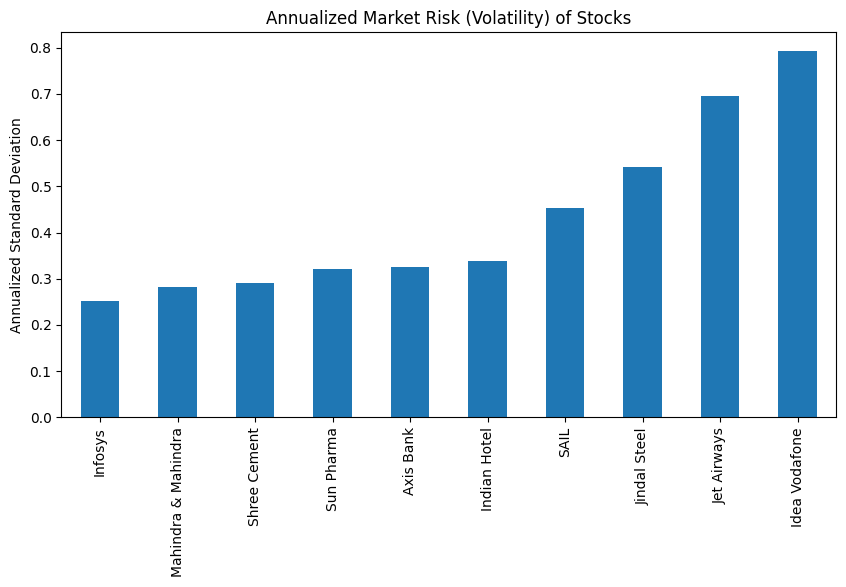

In [11]:
#Risk Comparison Across Stocks
risk_summary["Annualized_Risk"].sort_values().plot(
    kind="bar",
    figsize=(10,5),
    title="Annualized Market Risk (Volatility) of Stocks"
)

plt.ylabel("Annualized Standard Deviation")
plt.show()


## 9. Risk–Return Tradeoff

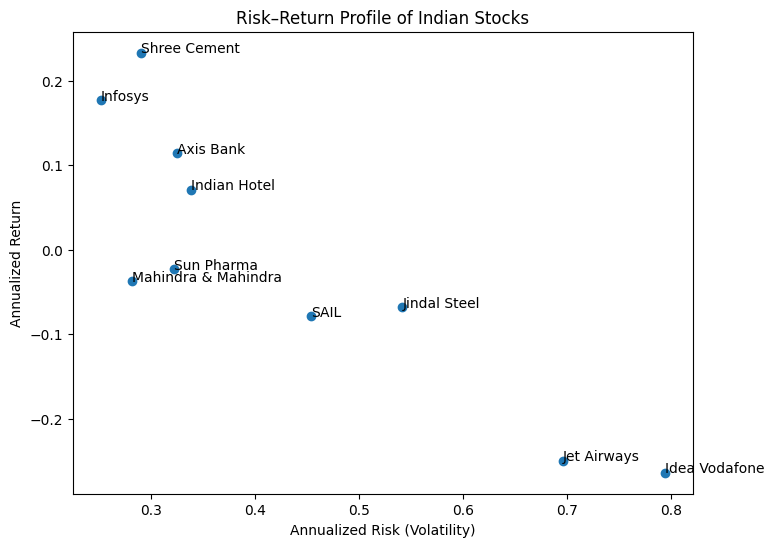

In [13]:
plt.figure(figsize=(8,6))
plt.scatter(
    risk_summary["Annualized_Risk"],
    risk_summary["Annualized_Return"]
)

for stock in risk_summary.index:
    plt.text(
        risk_summary.loc[stock, "Annualized_Risk"],
        risk_summary.loc[stock, "Annualized_Return"],
        stock
    )

plt.xlabel("Annualized Risk (Volatility)")
plt.ylabel("Annualized Return")
plt.title("Risk–Return Profile of Indian Stocks")
plt.show()



## Conclusion and Recommendation
From the analysis, we can observe the calculated mean and standard deviation of weekly returns, which are then annualized for a clearer perspective. For instance, Shree Cement shows the highest annualized return at approximately 0.233 (or 23.3%), while Idea Vodafone and Jet Airways exhibit significant negative annualized returns, -0.264 (-26.4%) and -0.250 (-25.0%) respectively. In terms of risk, measured by annualized standard deviation, Idea Vodafone stands out with the highest risk at around 0.794, followed by Jet Airways at 0.696. Conversely, Infosys appears to have the lowest annualized risk at 0.252, followed closely by Shree Cement at 0.290.

The bar chart titled "Annualized Market Risk (Volatility) of Stocks" visually reinforces these findings. As depicted, Idea Vodafone and Jet Airways clearly dominate the higher end of the risk spectrum, indicating they are significantly more volatile than other stocks. On the other end, Infosys, Mahindra & Mahindra, and Shree Cement are shown to have comparatively lower annualized risks, suggesting more stable price movements over the observed period.

Finally, the "Risk–Return Profile of Indian Stocks" scatter plot provides a crucial visual summary of the tradeoff between risk and return. This plot helps in identifying potentially attractive and unattractive investment opportunities. We can observe Shree Cement positioned favorably with a relatively high annualized return for a moderate level of annualized risk. Infosys also appears to be a good contender, offering a positive return with the lowest risk among the group. Conversely, Idea Vodafone and Jet Airways are located in the undesirable quadrant of high risk and negative returns, making them highly unattractive investments based on this analysis. Other stocks like Axis Bank offer positive returns but come with a higher risk profile than Infosys and Shree Cement, while Mahindra & Mahindra, SAIL, Sun Pharma, and Jindal Steel generally show lower or negative returns with varying levels of risk, indicating less attractive risk-return propositions compared to the top performers. This comprehensive view allows investors to quickly assess which stocks align with their risk tolerance and return expectations.

Based on the analysis and conclusion, here are some key recommendations for investors:

1. Consider Shree Cement and Infosys for Balanced Portfolios: Shree Cement offers a favorable risk-return profile with a relatively high annualized return for a moderate level of risk. Infosys also presents a strong case with positive returns and the lowest annualized risk among the analyzed stocks, making both suitable for investors seeking a balance between growth and stability.

2. Exercise Caution with Idea Vodafone and Jet Airways: These stocks are positioned in the undesirable quadrant of high risk and negative returns, indicating they are highly unattractive investments. Investors should avoid or significantly limit exposure to these assets.

3. Evaluate Other Stocks Based on Individual Risk Tolerance: Stocks like Axis Bank offer positive returns but come with a higher risk profile. Mahindra & Mahindra, SAIL, Sun Pharma, and Jindal Steel show lower or negative returns with varying risks. Investors should assess if the potential returns from these stocks justify their associated risk levels, aligning them with their personal investment goals and risk tolerance.

4. Prioritize Risk-Adjusted Returns: The analysis highlights the importance of not just looking at returns, but also at the risk taken to achieve those returns. Stocks that offer a good return for acceptable volatility are generally more desirable.

In [15]:
#create the directory
import os
os.makedirs("/content/outputs", exist_ok=True)

In [16]:
#verify its created
print(os.path.isdir("/content/outputs"))  # should be True

True


In [20]:
! jupyter nbconvert --to html /content/Market_Risk_Analysis.ipynb

[NbConvertApp] Converting notebook /content/Market_Risk_Analysis.ipynb to html
[NbConvertApp] WARNING | Alternative text is missing on 2 image(s).
[NbConvertApp] Writing 444366 bytes to /content/Market_Risk_Analysis.html
